# 03. Holt-Winters and ARIMA / SARIMA

**Goal:** fit the two classic time-series model families and check whether they are trustworthy.

- **Holt-Winters (exponential smoothing):** tracks a level, an optional trend and a weekly pattern, giving recent days more weight.
- **ARIMA / SARIMA:** models today's value from earlier values and earlier forecast errors. SARIMA adds a weekly (7-day) part.

**Plan**
1. Look at the series: is there a weekly pattern, is it stationary?
2. Fit Holt-Winters variants.
3. Choose a SARIMA order, using **training days only**.
4. Check the residuals.
5. Test on the last 30 days, next to the baselines from notebook 02.

The full test on many rolling origins is in notebook 04. A single window can mislead, as notebook 02 showed.

In [1]:
import warnings
from pathlib import Path
import itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

warnings.filterwarnings("ignore")   # statsmodels prints many convergence notices while searching; results are checked below

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
BROWN, RED, GREEN, GREY, BLUE = "#6F4E37", "#C1272D", "#2A7F62", "#8A8A8A", "#3B6EA5"

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for p in (FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.savefig(FIG / name, bbox_inches="tight")
    plt.show()

def metrics(actual, forecast):
    a, f = np.asarray(actual, float), np.asarray(forecast, float)
    ok = ~np.isnan(a) & ~np.isnan(f)
    a, f = a[ok], f[ok]
    return {"MAE": np.mean(np.abs(a - f)), "RMSE": np.sqrt(np.mean((a - f) ** 2)),
            "WAPE": np.sum(np.abs(a - f)) / np.sum(a),
            "SMAPE": np.mean(2 * np.abs(a - f) / (np.abs(a) + np.abs(f))),
            "Bias": np.mean(f - a), "n_days": int(ok.sum())}

daily = pd.read_csv(ROOT / "data" / "processed" / "daily_sales.csv", parse_dates=["date"], index_col="date")
y_raw = daily["revenue"].where(daily["reported"])      # NaN on the 7 days with no data
y = y_raw.interpolate(limit_direction="both")         # statsmodels needs a gap-free series
y.index.freq = "D"
print(f"{len(y)} days; {int(y_raw.isna().sum())} gaps filled by straight-line interpolation (those days are never used for scoring)")

388 days; 7 gaps filled by straight-line interpolation (those days are never used for scoring)


## 1. Look at the series

Weekly pattern? Trend? Is the series stationary (stable average and spread)?

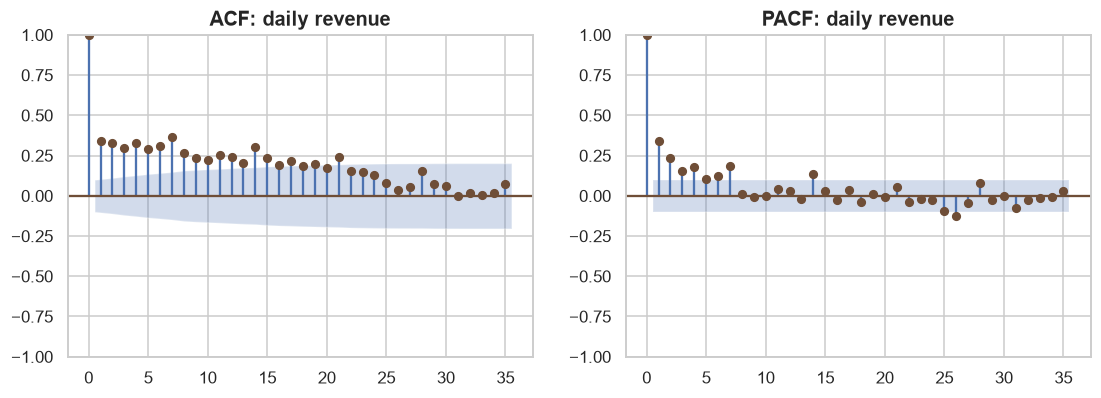

ADF test, daily revenue: statistic -3.00, p-value 0.034 -> stationary
ADF test, daily revenue, first difference: statistic -8.46, p-value 0.000 -> stationary
ACF at lags 6, 7, 8: 0.31 0.37 0.26 | lags 13, 14, 15: 0.2 0.31 0.24


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_acf(y, lags=35, ax=axes[0], color=BROWN); axes[0].set_title("ACF: daily revenue")
plot_pacf(y, lags=35, ax=axes[1], color=BROWN, method="ywm"); axes[1].set_title("PACF: daily revenue")
save_fig("11_acf_pacf.png")

def adf(series, label):
    stat, p, *_ = adfuller(series.dropna(), autolag="AIC")
    print(f"ADF test, {label}: statistic {stat:.2f}, p-value {p:.3f} -> {'stationary' if p < .05 else 'NOT stationary (cannot reject a unit root)'}")
adf(y, "daily revenue")
adf(y.diff(), "daily revenue, first difference")

from statsmodels.tsa.stattools import acf
a = acf(y, nlags=28)
print("ACF at lags 6, 7, 8:", a[6].round(2), a[7].round(2), a[8].round(2), "| lags 13, 14, 15:", a[13].round(2), a[14].round(2), a[15].round(2))

**Reading this:** the ACF falls slowly, which means today's revenue resembles the last few weeks (the level drifts over time). Small bumps at lags 7, 14 and 21 hint at a weekly pattern, but it is weak next to that drift. The ADF result is borderline, so differencing (`d = 1`) is worth trying.

## 2. Hold out the last 30 days

Everything below is fitted on the **training days only**. The last 30 days are the test (the same window as the Excel backtest).

In [3]:
H = 30
train, test = y.iloc[:-H], y.iloc[-H:]
test_raw = y_raw.iloc[-H:]
print("train:", train.index[0].date(), "to", train.index[-1].date(), f"({len(train)} days)")
print("test: ", test.index[0].date(), "to", test.index[-1].date(), f"({len(test)} days)")
forecasts = {}

train: 2024-03-01 to 2025-02-21 (358 days)
test:  2025-02-22 to 2025-03-23 (30 days)


## 3. Holt-Winters variants

Weekly seasonality (period 7) is always on. The variants differ in how they treat the trend:

| Variant | Trend |
|---|---|
| `HW_no_trend` | none: the forecast holds the latest level plus the weekday pattern |
| `HW_trend` | straight-line trend |
| `HW_damped` | trend that fades out over time |

Smoothing parameters are estimated by the library on the training days (the same job as Solver in the Excel workbook).

In [4]:
hw_specs = {
    "HW_no_trend": dict(trend=None),
    "HW_trend":    dict(trend="add"),
    "HW_damped":   dict(trend="add", damped_trend=True),
}
hw_fits, hw_rows = {}, []
for name, spec in hw_specs.items():
    fit = ExponentialSmoothing(train, seasonal="add", seasonal_periods=7, initialization_method="estimated", **spec).fit()
    hw_fits[name] = fit
    forecasts[name] = fit.forecast(H).values
    pr = fit.params
    hw_rows.append({"model": name, "alpha (level)": pr["smoothing_level"],
                    "beta (trend)": pr.get("smoothing_trend", np.nan),
                    "gamma (seasonal)": pr["smoothing_seasonal"],
                    "phi (damping)": pr.get("damping_trend", np.nan), "AIC": fit.aic})
hw_params = pd.DataFrame(hw_rows).set_index("model")
hw_params.round(4)

,alpha (level),beta (trend),gamma (seasonal),phi (damping),AIC
model,,,,,
HW_no_trend,0.1670,NaN,0.0,NaN,3520.7772
HW_trend,0.1649,0.0,0.0,NaN,3524.2945
HW_damped,0.1646,0.0,0.0,0.9054,3526.1143


**Reading this:**
- **beta = 0** means the model does not want a trend, the same as in the Excel workbook.
- **gamma = 0** means the library kept the starting weekday pattern and never updated it. The Excel workbook (fitted by squared error, not likelihood) found gamma about 0.14, so the two tools disagree a little. The weekly pattern is weak and its estimate is not stable.
- AIC cannot compare these models with SARIMA below (different likelihoods); the test days decide.

## 4. Choose a SARIMA order (training days only)

A small grid is searched and the order with the lowest **AIC** is kept. AIC rewards fit but penalises complexity. It is computed on the training days only, so the test days stay unseen.

In [5]:
t0 = time.time()
grid = []
for p, d, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1], [0, 1], [0, 1]):
    if (p, d, q, P, Q) == (0, 0, 0, 0, 0):
        continue
    try:
        res = SARIMAX(train, order=(p, d, q), seasonal_order=(P, 0, Q, 7)).fit(disp=False, maxiter=100)
        grid.append({"order": (p, d, q), "seasonal": (P, 0, Q, 7), "AIC": res.aic, "BIC": res.bic})
    except Exception as e:
        pass
grid = pd.DataFrame(grid).sort_values("AIC").reset_index(drop=True)
print(f"{len(grid)} SARIMA models fitted in {time.time() - t0:.0f} s")
grid.head(8).round(1)

47 SARIMA models fitted in 27 s


,order,seasonal,AIC,BIC
0,"(0, 1, 1)","(0, 0, 0, 7)",4521.2,4528.9
1,"(1, 1, 1)","(0, 0, 0, 7)",4523.0,4534.6
2,"(0, 1, 1)","(1, 0, 0, 7)",4523.2,4534.8
3,"(0, 1, 1)","(0, 0, 1, 7)",4523.2,4534.8
4,"(0, 1, 1)","(1, 0, 1, 7)",4524.8,4540.3
5,"(2, 1, 1)","(0, 0, 0, 7)",4525.0,4540.5
6,"(1, 1, 1)","(1, 0, 0, 7)",4525.0,4540.5
7,"(1, 1, 1)","(0, 0, 1, 7)",4525.0,4540.5


In [6]:
best = grid.iloc[0]
print("Best by AIC:", best["order"], best["seasonal"])
sarima = SARIMAX(train, order=best["order"], seasonal_order=best["seasonal"]).fit(disp=False, maxiter=200)
arima = ARIMA(train, order=(1, 1, 1)).fit()          # plain ARIMA with no weekly part, as a comparison
forecasts["SARIMA_best_AIC"] = sarima.get_forecast(H).predicted_mean.values
forecasts["ARIMA_111"] = arima.get_forecast(H).predicted_mean.values
print(sarima.summary().tables[1])

Best by AIC: (0, 1, 1) (0, 0, 0, 7)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8337      0.028    -30.314      0.000      -0.888      -0.780
sigma2      1.825e+04   1197.745     15.241      0.000    1.59e+04    2.06e+04


## 5. Residual checks

If a model captured the pattern, its residuals (the leftover errors) should look like random noise: no leftover autocorrelation and roughly bell-shaped.

Ljung-Box test (small p-value = leftover autocorrelation):


,lb_stat,lb_pvalue
7,1.345,0.987
14,5.025,0.985


Shapiro-Wilk normality test: p = 0.0002 -> residuals are not normal (long tail / skew)


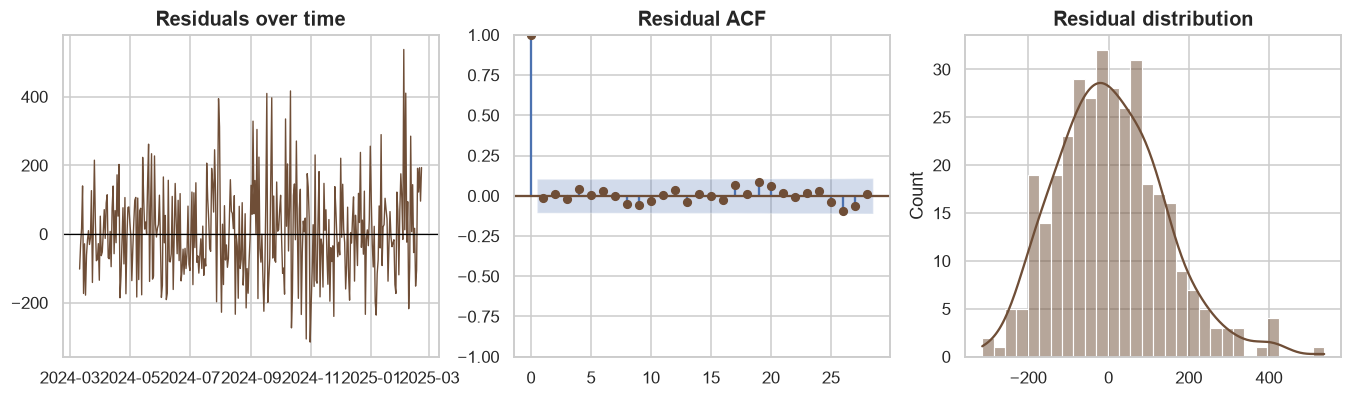

In [7]:
resid = sarima.resid.iloc[10:]          # skip the first days while the model is warming up
lb = acorr_ljungbox(resid, lags=[7, 14], return_df=True)
print("Ljung-Box test (small p-value = leftover autocorrelation):")
display(lb.round(3))
sh = stats.shapiro(resid)
print(f"Shapiro-Wilk normality test: p = {sh.pvalue:.4f} -> residuals {'look normal' if sh.pvalue > .05 else 'are not normal (long tail / skew)'}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(resid.index, resid, color=BROWN, lw=.9); axes[0].axhline(0, color="black", lw=.8); axes[0].set_title("Residuals over time")
plot_acf(resid, lags=28, ax=axes[1], color=BROWN); axes[1].set_title("Residual ACF")
sns.histplot(resid, bins=30, kde=True, color=BROWN, ax=axes[2]); axes[2].set_title("Residual distribution")
save_fig("12_sarima_residuals.png")

**Reading this:** a few large residuals are expected, because some days are very busy or very quiet. What matters is whether the Ljung-Box p-values are small (leftover pattern) and whether the spread of the residuals looks stable over time. Long runs of residuals with the same sign would point to level shifts that the model reacted to late.

## 6. Test on the last 30 days

In [8]:
baseline_last = pd.read_csv(TAB / "baseline_30day_last_window.csv", index_col=0)

rows = {name: metrics(test_raw, f) for name, f in forecasts.items()}
res_last = pd.DataFrame(rows).T.sort_values("MAE")
display(res_last.round(3))

compare = pd.concat([
    res_last[["MAE", "WAPE", "Bias"]].assign(family="HW / ARIMA"),
    baseline_last.loc[["seasonal_naive", "weekday_avg_4w", "mean_7d"], ["MAE", "WAPE", "Bias"]].assign(family="baseline"),
]).sort_values("MAE")
compare.round(3)

,MAE,RMSE,WAPE,SMAPE,Bias,n_days
HW_damped,165.080,198.145,0.379,0.400,94.577,30.0
HW_no_trend,165.399,198.843,0.379,0.400,95.909,30.0
SARIMA_best_AIC,168.289,207.117,0.386,0.404,97.723,30.0
ARIMA_111,168.639,208.587,0.387,0.404,101.171,30.0
HW_trend,169.365,206.546,0.388,0.406,111.609,30.0


,MAE,WAPE,Bias,family
weekday_avg_4w,76.339,0.175,-33.118,baseline
seasonal_naive,101.383,0.232,74.471,baseline
HW_damped,165.080,0.379,94.577,HW / ARIMA
HW_no_trend,165.399,0.379,95.909,HW / ARIMA
mean_7d,167.165,0.383,89.294,baseline
SARIMA_best_AIC,168.289,0.386,97.723,HW / ARIMA
ARIMA_111,168.639,0.387,101.171,HW / ARIMA
HW_trend,169.365,0.388,111.609,HW / ARIMA


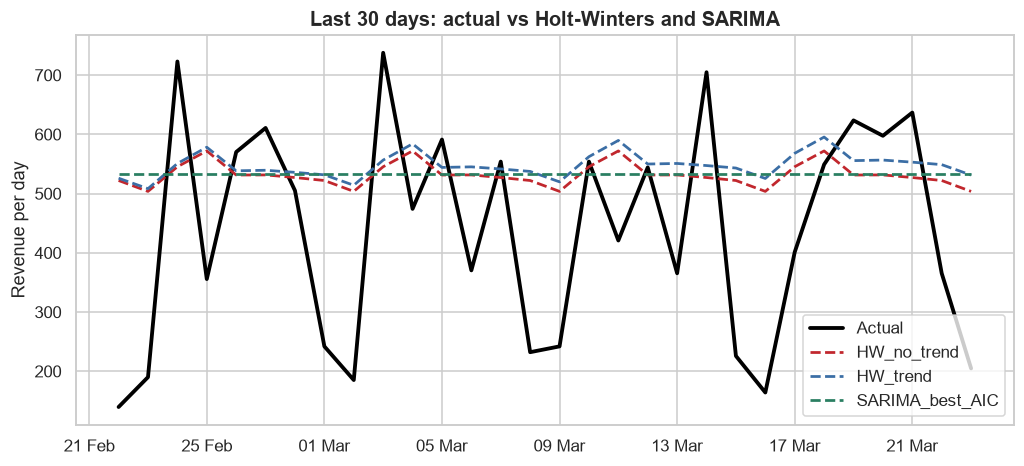

In [9]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(test.index, test_raw, color="black", lw=2.5, label="Actual")
for name, c in zip(["HW_no_trend", "HW_trend", "SARIMA_best_AIC"], [RED, BLUE, GREEN]):
    ax.plot(test.index, forecasts[name], ls="--", lw=1.8, color=c, label=name)
ax.set(title="Last 30 days: actual vs Holt-Winters and SARIMA", ylabel="Revenue per day")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend()
save_fig("13_hw_arima_last_window.png")

## 7. Prediction interval check

SARIMA 95% interval contains 83% of the actual test days (target: about 95%)


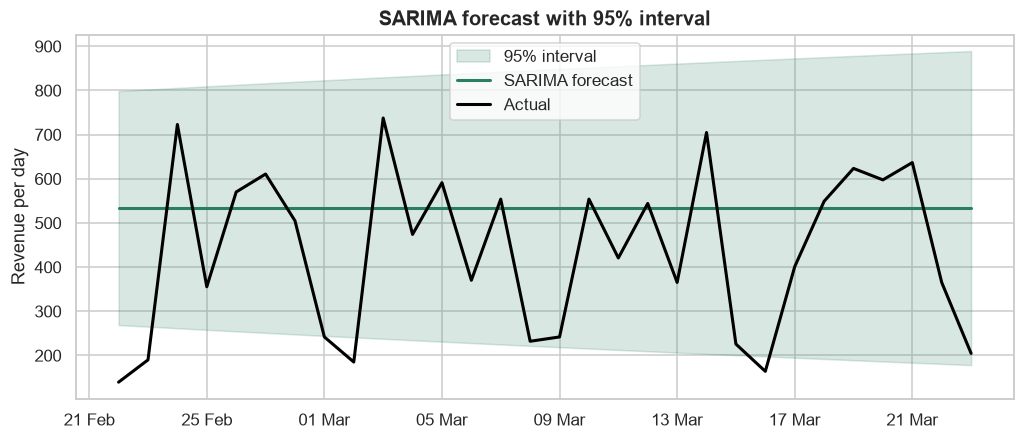

In [10]:
fc = sarima.get_forecast(H)
ci = fc.conf_int(alpha=.05)
inside = ((test_raw.values >= ci.iloc[:, 0].values) & (test_raw.values <= ci.iloc[:, 1].values))[~test_raw.isna().values]
print(f"SARIMA 95% interval contains {inside.mean():.0%} of the actual test days (target: about 95%)")

fig, ax = plt.subplots(figsize=(11, 4.3))
ax.fill_between(test.index, ci.iloc[:, 0], ci.iloc[:, 1], color=GREEN, alpha=.18, label="95% interval")
ax.plot(test.index, fc.predicted_mean, color=GREEN, lw=2, label="SARIMA forecast")
ax.plot(test.index, test_raw, color="black", lw=2, label="Actual")
ax.set(title="SARIMA forecast with 95% interval", ylabel="Revenue per day"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend()
save_fig("14_sarima_interval.png")

## 8. Save results and findings

In [11]:
hw_params.round(4).to_csv(TAB / "hw_parameters.csv")
grid.head(10).to_csv(TAB / "sarima_grid_top10.csv", index=False)
res_last.round(4).to_csv(TAB / "hw_arima_last_window.csv")

b = res_last.index[0]
print(f"1. Weekly pattern is weak: ACF is {a[7]:.2f} at lag 7 against {a[6]:.2f} and {a[8]:.2f} next to it. Most autocorrelation is the drifting level.")
print(f"2. Holt-Winters estimates: beta = {hw_params.loc['HW_trend', 'beta (trend)']:.3f} (no trend wanted), gamma = {hw_params.loc['HW_no_trend', 'gamma (seasonal)']:.3f} (weekday pattern not updated).")
print(f"3. SARIMA order chosen on training days by AIC: {best['order']} x {best['seasonal']} "
      f"({'no weekly part selected' if best['seasonal'][0] == 0 and best['seasonal'][2] == 0 else 'with a weekly part'}).")
print(f"4. Last 30 days: best of HW/ARIMA is {b} (MAE {res_last.loc[b, 'MAE']:.1f}, WAPE {res_last.loc[b, 'WAPE']:.0%}); "
      f"best baseline there was weekday_avg_4w (MAE {baseline_last.loc['weekday_avg_4w', 'MAE']:.1f}).")
print(f"4b. Bias of the HW / ARIMA models on the last window: {res_last['Bias'].min():+.0f} to {res_last['Bias'].max():+.0f} per day (positive = forecast above actual).")
print(f"5. SARIMA 95% interval coverage on the test days: {inside.mean():.0%}.")
print(f"6. Residual check: Ljung-Box p at lag 7 = {lb.loc[7, 'lb_pvalue']:.3f}; Shapiro p = {sh.pvalue:.4f}.")
print("7. One window is not enough to rank models. Notebook 04 repeats this over many rolling origins.")

1. Weekly pattern is weak: ACF is 0.37 at lag 7 against 0.31 and 0.26 next to it. Most autocorrelation is the drifting level.
2. Holt-Winters estimates: beta = 0.000 (no trend wanted), gamma = 0.000 (weekday pattern not updated).
3. SARIMA order chosen on training days by AIC: (0, 1, 1) x (0, 0, 0, 7) (no weekly part selected).
4. Last 30 days: best of HW/ARIMA is HW_damped (MAE 165.1, WAPE 38%); best baseline there was weekday_avg_4w (MAE 76.3).
4b. Bias of the HW / ARIMA models on the last window: +95 to +112 per day (positive = forecast above actual).
5. SARIMA 95% interval coverage on the test days: 83%.
6. Residual check: Ljung-Box p at lag 7 = 0.987; Shapiro p = 0.0002.
7. One window is not enough to rank models. Notebook 04 repeats this over many rolling origins.


## Next

`04_backtesting_and_comparison.ipynb` tests Holt-Winters, SARIMA and the baselines on the same rolling origins and builds the final comparison table.